In [2]:
import os
while "src" not in os.listdir():
    os.chdir("..")
    
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
 
import mygene

from src.reading_in import read_in_proteins, _load_essential_proteins

In [3]:
exclude_proteins = [
    "YBR010W", "YJL177W", "YGR220C", "YIL018W"
]

good_proteins = [
    "YHL027W", "YDR320C"
]

In [4]:
PEP5 = "YMR231W"
G = read_in_proteins(connected=True)
essential_proteins = _load_essential_proteins("data/raw/EssentialProteins_YeastMine_cerevisiae.csv")

MIN_DISTANCE = 4
MAX_DISTANCE = np.inf

distances = nx.single_source_shortest_path_length(G, PEP5)

# Select proteins whose shortest-path distance is 3, 4, or 5
candidate_nodes = {
    node: distance
    for node, distance in distances.items()
    if MIN_DISTANCE <= distance <= MAX_DISTANCE
    and node not in essential_proteins # no essential proteins!
}

communities = nx.community.louvain_communities(G, resolution=40, seed=0)
# Find the community containing Pep5
pep5_community = next(
    community for community in communities
    if PEP5 in community
)

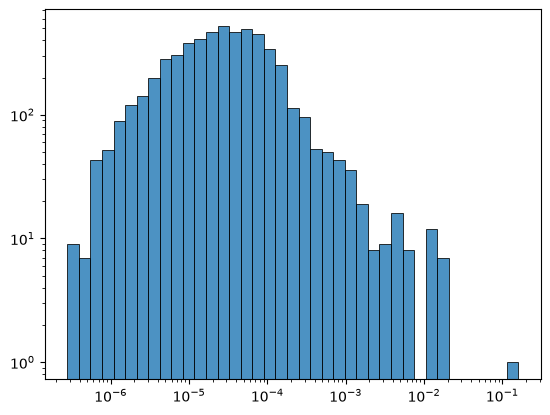

In [5]:
personalizaiton_vector = {PEP5 : 1}

pagerank = nx.pagerank(G, alpha=0.85, personalization=personalizaiton_vector)

distribution = np.array(list(pagerank.values()))
distribution = distribution[0 < distribution]

bins = np.logspace(np.log10(distribution.min()), np.log10(distribution.max()), 40)
plt.hist(
    distribution,
    bins=bins,
    edgecolor="black",
    linewidth=0.7,
    alpha=0.8
)

plt.xscale("log")
plt.yscale("log")

plt.show()

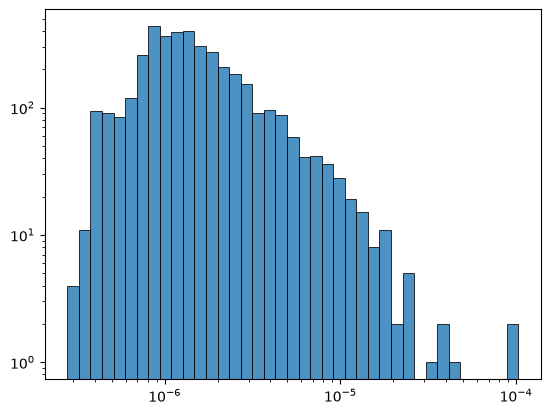

In [6]:
pagerank_degree = {
    node : rank / G.degree(node)
    for node, rank in pagerank.items()
    if node in candidate_nodes
    and node not in essential_proteins
    and node not in exclude_proteins
}

distribution = np.array(list(pagerank_degree.values()))
distribution = distribution[0 < distribution]

bins = np.logspace(np.log10(distribution.min()), np.log10(distribution.max()), 40)
plt.hist(
    distribution,
    bins=bins,
    edgecolor="black",
    linewidth=0.7,
    alpha=0.8
)

plt.xscale("log")
plt.yscale("log")

plt.show()

In [7]:
for node, score in sorted(
    pagerank_degree.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]:
    print(
        f"{node}: "
        f"distance = {candidate_nodes[node]}, "
        f"pagerank = {score}"
    )


YKL047W: distance = 4, pagerank = 0.0001028368793931891
YPL199C: distance = 4, pagerank = 0.0001028368793931891
YGL223C: distance = 4, pagerank = 4.159522292158929e-05
YMR282C: distance = 4, pagerank = 4.012511112699099e-05
YCL048W: distance = 4, pagerank = 3.594493944856914e-05
YBR129C: distance = 4, pagerank = 3.5232441963697205e-05
YPL085W: distance = 4, pagerank = 2.573276960200826e-05
YOR216C: distance = 4, pagerank = 2.4096365659722042e-05
YPR097W: distance = 4, pagerank = 2.3190446773340274e-05
YCR067C: distance = 4, pagerank = 2.311581124021046e-05


In [8]:
print(pagerank_degree[good_proteins[0]])
print(pagerank_degree[good_proteins[1]])

4.687577185260906e-06


KeyError: 'YDR320C'

In [9]:
mg = mygene.MyGeneInfo()
mg.getgene('YGL223C')

{'AllianceGenome': 'SGD:S000003191',
 'FungiDB': 'YGL223C',
 'SGD': 'S000003191',
 'VEuPathDB': 'YGL223C',
 '_id': '852649',
 '_version': 1,
 'accession': {'genomic': ['BK006941.2', 'NC_001139.9'],
  'protein': ['DAA07896.1', 'NP_011292.1', 'P53079.1'],
  'rna': 'NM_001181088.1',
  'translation': {'protein': 'NP_011292.1', 'rna': 'NM_001181088.1'}},
 'alias': ['COD3', 'LDB11', 'SEC36'],
 'ensembl': {'gene': 'YGL223C',
  'protein': 'YGL223C',
  'transcript': 'YGL223C_mRNA',
  'translation': [{'protein': 'YGL223C', 'rna': 'YGL223C_mRNA'}],
  'type_of_gene': 'protein_coding'},
 'entrezgene': '852649',
 'generif': [{'pubmed': 15932880,
   'text': 'Cog1p has a critical role in the organization of the yeast conserved oligomeric Golgi complex'},
  {'pubmed': 23603116,
   'text': 'Data indicate that Cog1, a subunit of the Golgi-associated COG complex, is also shown to contain an Ac/N-degron interacts with Cog2, Cog3 and Cog4.'}],
 'genomic_pos': {'chr': 'VII',
  'end': 80365,
  'ensemblgene': 